# TRCA 跨文件分类
直接使用 `data/eeg_trials_*.npy` 和 `data/eeg_labels_*.npy`。不读取 PsychoPy 时序记录，也不做掉帧筛选。

In [34]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.linalg import eigh
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix


In [35]:
# 只需要修改这里两个文件名（不写 .npy 后缀）
train_name = 'test_2_ssvep'
test_name = 'test_3_ssvep'

freqs = np.array([15, 12, 10])
data_dir = Path('data')


In [36]:
def load_dataset(name):
    x = np.load(data_dir / f'eeg_trials_{name}.npy', allow_pickle=True)
    y = np.load(data_dir / f'eeg_labels_{name}.npy').astype(int)
    x = np.asarray(x, dtype=np.float64)
    if x.ndim != 3:
        raise ValueError(f'{name}: EEG应为[trial, channel, sample]，实际为{x.shape}')
    if len(x) != len(y):
        raise ValueError(f'{name}: EEG数量{len(x)}与标签数量{len(y)}不一致')
    if not np.all(np.isfinite(x)):
        raise ValueError(f'{name}: EEG包含NaN或无穷值')
    return x, y

X_train, y_train = load_dataset(train_name)
X_test, y_test = load_dataset(test_name)

# TRCA模板要求训练集和测试集长度一致，统一截取共同长度。
n_samples = min(X_train.shape[2], X_test.shape[2])
X_train = X_train[:, :, :n_samples]
X_test = X_test[:, :, :n_samples]

print('训练集:', train_name, X_train.shape, '类别数:', np.bincount(y_train, minlength=len(freqs)))
print('测试集:', test_name, X_test.shape, '类别数:', np.bincount(y_test, minlength=len(freqs)))


训练集: test_2_ssvep (19, 8, 373) 类别数: [8 4 7]
测试集: test_3_ssvep (41, 8, 373) 类别数: [11 16 14]


In [37]:
def pearson_corr(a, b):
    a = np.asarray(a, dtype=np.float64).ravel()
    b = np.asarray(b, dtype=np.float64).ravel()
    a = a - a.mean()
    b = b - b.mean()
    denominator = np.linalg.norm(a) * np.linalg.norm(b)
    return 0.0 if denominator <= 1e-12 else float(a @ b / denominator)


def train_trca_one_class(class_trials):
    # class_trials: [trial, channel, sample]
    centered = class_trials - class_trials.mean(axis=2, keepdims=True)
    summed = centered.sum(axis=0)

    # Q = sum_i Xi Xi.T
    Q = np.einsum('nct,ndt->cd', centered, centered)
    # S = sum_{i != j} Xi Xj.T
    S = summed @ summed.T - Q

    scale = max(float(np.trace(Q)) / Q.shape[0], 1.0)
    Q_reg = Q + 1e-6 * scale * np.eye(Q.shape[0])
    _, eigenvectors = eigh(S, Q_reg)
    w = eigenvectors[:, -1]
    w = w / (np.linalg.norm(w) + 1e-12)
    template = centered.mean(axis=0)
    return w, template


def train_trca(X, y, n_classes):
    model = []
    for label in range(n_classes):
        class_trials = X[y == label]
        if len(class_trials) < 2:
            raise ValueError(f'类别{label}至少需要2个训练trial，当前只有{len(class_trials)}个')
        model.append(train_trca_one_class(class_trials))
    return model


def predict_trca(X, model):
    predictions = []
    all_scores = []
    for trial in X:
        trial = trial - trial.mean(axis=1, keepdims=True)
        scores = [
            pearson_corr(w @ trial, w @ template)
            for w, template in model
        ]
        predictions.append(int(np.argmax(scores)))
        all_scores.append(scores)
    return np.asarray(predictions), np.asarray(all_scores)



TRCA跨文件准确率: 41/41 = 100.00%
15 Hz: 11/11 = 100.00%
12 Hz: 16/16 = 100.00%
10 Hz: 14/14 = 100.00%


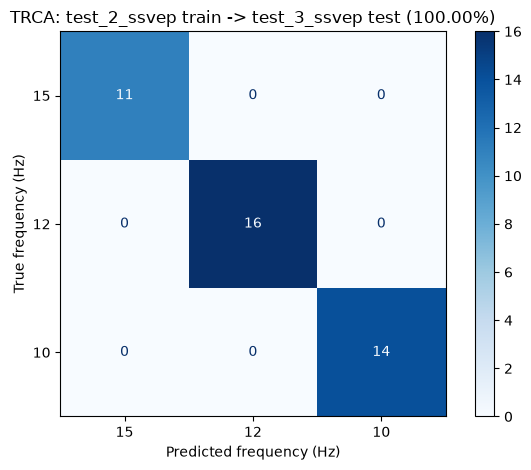

In [38]:
model = train_trca(X_train, y_train, len(freqs))
y_pred, scores = predict_trca(X_test, model)

accuracy = np.mean(y_pred == y_test)
print(f'\nTRCA跨文件准确率: {np.sum(y_pred == y_test)}/{len(y_test)} = {accuracy:.2%}')
for label, freq in enumerate(freqs):
    mask = y_test == label
    class_accuracy = np.mean(y_pred[mask] == y_test[mask]) if np.any(mask) else np.nan
    print(f'{freq} Hz: {np.sum(y_pred[mask] == y_test[mask])}/{np.sum(mask)} = {class_accuracy:.2%}')

cm = confusion_matrix(y_test, y_pred, labels=np.arange(len(freqs)))
disp = ConfusionMatrixDisplay(cm, display_labels=freqs)
disp.plot(cmap='Blues', values_format='d')
plt.title(f'TRCA: {train_name} train -> {test_name} test ({accuracy:.2%})')
plt.xlabel('Predicted frequency (Hz)')
plt.ylabel('True frequency (Hz)')
plt.tight_layout()
plt.show()


In [39]:
# 查看每个测试trial的预测结果和三个类别分数
for i, (true_label, pred_label, trial_scores) in enumerate(zip(y_test, y_pred, scores), start=1):
    print(
        f'trial {i:03d}: true={freqs[true_label]:g} Hz, '
        f'pred={freqs[pred_label]:g} Hz, scores={np.round(trial_scores, 4)}'
    )


trial 001: true=10 Hz, pred=10 Hz, scores=[-0.0162 -0.0092  0.5529]
trial 002: true=12 Hz, pred=12 Hz, scores=[-0.0103  0.4865  0.0095]
trial 003: true=10 Hz, pred=10 Hz, scores=[ 0.0309 -0.1036  0.5612]
trial 004: true=12 Hz, pred=12 Hz, scores=[0.0784 0.4931 0.096 ]
trial 005: true=15 Hz, pred=15 Hz, scores=[ 0.7229 -0.0066  0.096 ]
trial 006: true=10 Hz, pred=10 Hz, scores=[ 0.0597 -0.0477  0.5293]
trial 007: true=10 Hz, pred=10 Hz, scores=[0.1515 0.0209 0.5534]
trial 008: true=12 Hz, pred=12 Hz, scores=[0.0852 0.5404 0.1209]
trial 009: true=15 Hz, pred=15 Hz, scores=[ 0.7474 -0.0756  0.1005]
trial 010: true=12 Hz, pred=12 Hz, scores=[0.0136 0.5802 0.0833]
trial 011: true=10 Hz, pred=10 Hz, scores=[0.0296 0.1425 0.613 ]
trial 012: true=10 Hz, pred=10 Hz, scores=[-0.064   0.0209  0.6555]
trial 013: true=15 Hz, pred=15 Hz, scores=[ 0.7458  0.0974 -0.0812]
trial 014: true=12 Hz, pred=12 Hz, scores=[ 0.0862  0.5857 -0.068 ]
trial 015: true=15 Hz, pred=15 Hz, scores=[0.6357 0.0467 0.1778